# Objectif 

L'objectif est de comprendre le biais d'environ 67 secondes observé le long de la trajectoire AIS du navire dans le cas active / passive_ais (cf. acouplane_portion5_active_passive_ais_time_bias.ipynb).



**Date de création** : 24/11/2026

In [2]:
import os
import sys
import glob
import numpy as np
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Rectangle

from scipy.io import loadmat
from matplotlib.lines import Line2D
from datetime import datetime, timedelta

In [3]:
if os.name == "nt":  # Windows
    ROOT_PROGRAM = r"C:\Users\baptiste.menetrier\Desktop\devPy\phd"
else:  # Linux
    ROOT_PROGRAM = "/home/program/ubf_tools"
sys.path.append(ROOT_PROGRAM)

from real_data_analysis.acouplane.src.acouplane_cst import (
    ACOUPLANE_PORTION_NC_ROOT_FPATH,
    ACOUPLANE_POSITIONS_NC_FPATH,
    ACOUPLANE_PRESSURE_NC_FPATH,
    AIS_FPATH,
)

from real_data_analysis.acouplane.src.acouplane_plot_mfp import (
    plot_combined_intersection_ambiguity,
    _combined_surfaces_and_positions,
)
from real_data_analysis.acouplane.src.acouplane_plot_portion import (
    plot_portion_tir_pos,
    plot_pressure_section,
    plot_spectrogram_section,
    plot_obs_pos,
)
from real_data_analysis.acouplane.src.acouplane_portion_io import (
    section_name_of,
)

from real_data_analysis.acouplane.src.acouplane_utils import (
    plot_obs_pos,
    extract_pressure_section,
    convert_raw_pressure_to_physical_units,
)


# Chargement des données 

## Données de positions 
Toutes les données disponibles : 

* Données AIS 
* Données de l'ATALANTE 

In [4]:
ds_pos = xr.open_dataset(ACOUPLANE_POSITIONS_NC_FPATH)
ds_pos

<xarray.Dataset> Size: 524MB
Dimensions:                (rcv_id: 7, atl_datetime: 563739, mmsi: 525,
                            ais_datetime: 60451, src_datetime: 33608)
Coordinates:
  * rcv_id                 (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
  * atl_datetime           (atl_datetime) datetime64[ns] 5MB 2026-02-24 ... 2...
  * mmsi                   (mmsi) int64 4kB 4 127 128 129 396 ... 431 125 32 244
  * ais_datetime           (ais_datetime) datetime64[ns] 484kB 2026-02-24 ......
  * src_datetime           (src_datetime) datetime64[ns] 269kB 2026-02-24T20:...
Data variables: (12/16)
    rcv_lon                (rcv_id) float64 56B ...
    rcv_lat                (rcv_id) float64 56B ...
    rcv_immersion          (rcv_id) int16 14B ...
    rcv_lon_apriori        (rcv_id) float64 56B ...
    rcv_lat_apriori        (rcv_id) float64 56B ...
    rcv_immersion_apriori  (rcv_id) int16 14B ...
    ...                     ...
    tir_SEGD               (src_datetime) int64 269kB ...
    tir_ECOS               (src_datetime) int64 269kB ...
    tir_src_lon            (src_datetime) float64 269kB ...
    tir_src_lat            (src_datetime) float64 269kB ...
    tir_vessel_lon         (src_datetime) float64 269kB ...
    tir_vessel_lat         (src_datetime) float64 269kB ...
Attributes:
    description:              Positions AIS interpolées
    interpolation_time_step:  10s
    campagne:                 ACOUPLANE
    geodesic_frame:           WGS84

## Définition d'une zone d'intérêt

On commence par définir la zone de recherche.

In [5]:
# Step 1: select AIS pos in the area of interest
lon_offset_percentage = lat_offset_percentage = 0.0025

rcv_id_for_area_def = [
    "obs1",
    "obs2",
    "obs4",
    "obs7",
    "obs5",
    # "obs6",
]  # Remove OBS 6 to reduce area
ds_pos_area = ds_pos.sel(rcv_id=rcv_id_for_area_def)

# rcv_network_center_lon, rcv_network_center_lat = (
#     ds_pos_area.rcv_lon.mean().values,
#     ds_pos_area.rcv_lat.mean().values,
# )
# lon_min, lon_max = ds_pos_area.rcv_lon.min().values * (
#     1 - lon_offset_percentage / 2
# ), ds_pos_area.rcv_lon.max().values * (1 + lon_offset_percentage / 2)
# lat_min, lat_max = ds_pos_area.rcv_lat.min().values * (
#     1 - lat_offset_percentage / 2
# ), ds_pos_area.rcv_lat.max().values * (1 + lat_offset_percentage / 2)

# lon_min, lon_max, lat_min, lat_max



In [6]:
lon_min, lon_max, lat_min, lat_max = 5.925, 6.07, 42.90, 43.08

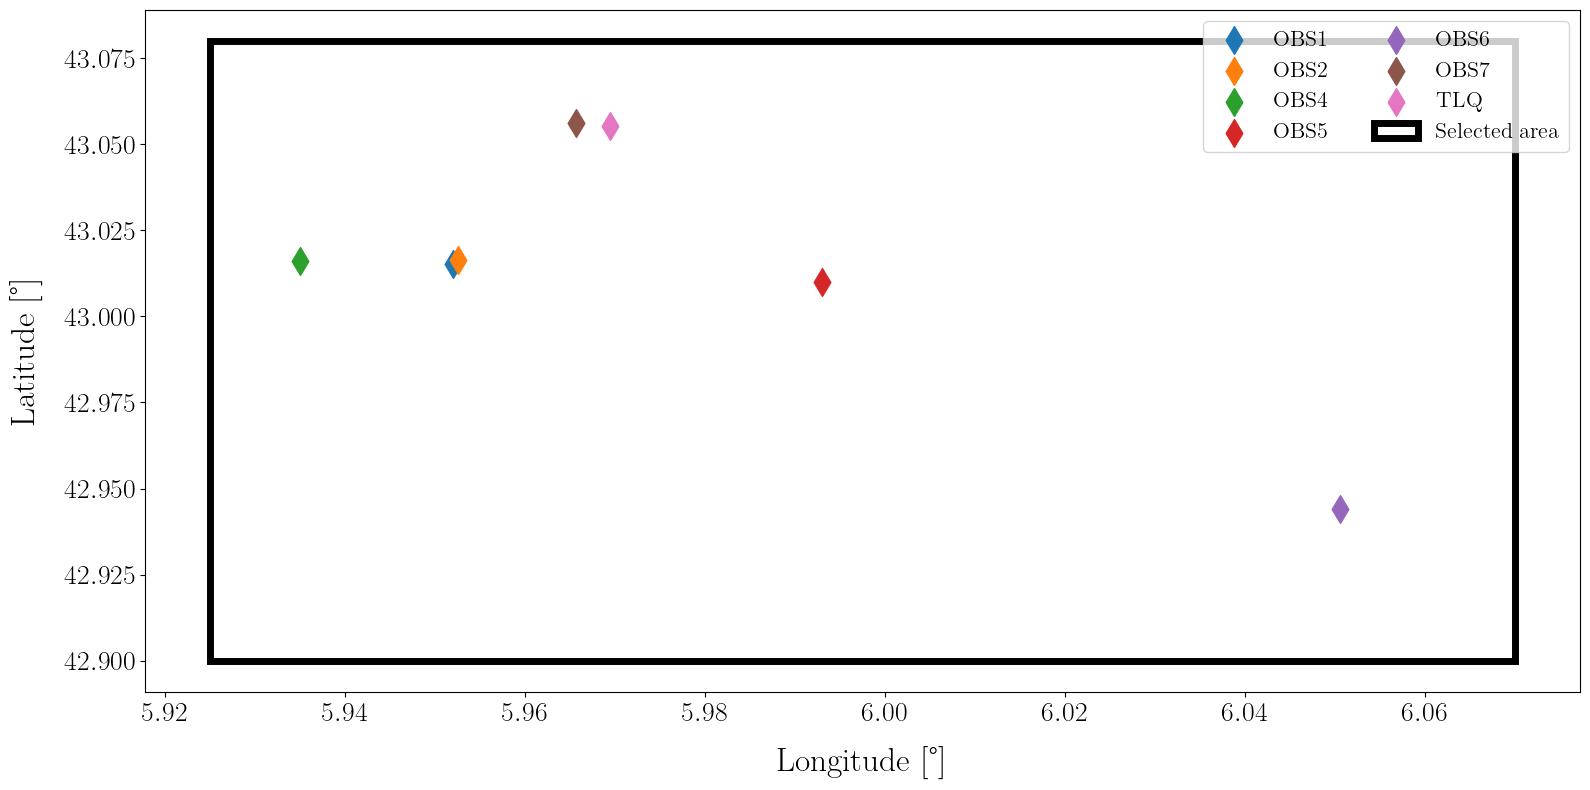

In [7]:
# Illustrate on map
fig, ax = plt.subplots(1, 1, figsize=(16, 8))
_ = plot_obs_pos(ds_pos, ax=ax)
ax.add_patch(
    Rectangle(
        (lon_min, lat_min),
        lon_max - lon_min,
        lat_max - lat_min,
        fc="none",
        ec="k",
        lw=5,
        label="Selected area",
    )
)
ax.set_title("")
ax.legend()
legend = ax.get_legend()

if legend is not None:
    handles = legend.legend_handles
    labels = [text.get_text() for text in legend.get_texts()]

    legend.remove()

    ax.legend(
        handles,
        labels,
        loc="upper right",
        fontsize=16,
        ncols=2,
    )

## Position AIS 

On extrait ensuite les positions AIS qui passe dans la boite définie. 

In [8]:
ds_ais = ds_pos.copy().drop_vars(
    [
        v
        for v in list(ds_pos.variables)
        if v
        not in [
            "ais_lon",
            "ais_lat",
            "ais_datetime",
            "mmsi",
        ]
    ]
)
ds_ais

mask = (
    (ds_ais["ais_lon"] >= lon_min)
    & (ds_ais["ais_lon"] <= lon_max)
    & (ds_ais["ais_lat"] >= lat_min)
    & (ds_ais["ais_lat"] <= lat_max)
)

# Mask and drop coordinates that have no positions in the area
ds_ais_in_area = (
    ds_ais.where(mask).dropna("ais_datetime", how="all").dropna("mmsi", how="all")
)
# Add mmsi to ease selection
# ds_ais_in_area
# ds_ais_in_area = ds_ais_in_area.assign_coords(mmsi=np.arange(ds_ais_in_area.sizes["mmsi"]))
ds_ais_in_area

<xarray.Dataset> Size: 103MB
Dimensions:       (mmsi: 154, ais_datetime: 41464)
Coordinates:
  * mmsi          (mmsi) int64 1kB 9 130 376 532 455 131 ... 96 106 196 505 419
  * ais_datetime  (ais_datetime) datetime64[ns] 332kB 2026-02-24T01:24:30 ......
Data variables:
    ais_lon       (mmsi, ais_datetime) float64 51MB nan nan nan ... nan nan nan
    ais_lat       (mmsi, ais_datetime) float64 51MB nan nan nan ... nan nan nan
Attributes:
    description:              Positions AIS interpolées
    interpolation_time_step:  10s
    campagne:                 ACOUPLANE
    geodesic_frame:           WGS84

In [9]:
missing_vars = [
    "rcv_id",
    "rcv_lon",
    "rcv_lat",
    "rcv_immersion",
]
for var in missing_vars:
    ds_ais_in_area[var] = ds_pos[var]

In [10]:
ds_ais_in_area

<xarray.Dataset> Size: 103MB
Dimensions:        (mmsi: 154, ais_datetime: 41464, rcv_id: 7)
Coordinates:
  * mmsi           (mmsi) int64 1kB 9 130 376 532 455 131 ... 96 106 196 505 419
  * ais_datetime   (ais_datetime) datetime64[ns] 332kB 2026-02-24T01:24:30 .....
  * rcv_id         (rcv_id) <U4 112B 'obs1' 'obs2' 'obs4' ... 'obs7' 'tlq'
Data variables:
    ais_lon        (mmsi, ais_datetime) float64 51MB nan nan nan ... nan nan nan
    ais_lat        (mmsi, ais_datetime) float64 51MB nan nan nan ... nan nan nan
    rcv_lon        (rcv_id) float64 56B ...
    rcv_lat        (rcv_id) float64 56B ...
    rcv_immersion  (rcv_id) int16 14B ...
Attributes:
    description:              Positions AIS interpolées
    interpolation_time_step:  10s
    campagne:                 ACOUPLANE
    geodesic_frame:           WGS84

## Données de pression 

In [11]:
ds_pressure = xr.open_dataset(ACOUPLANE_PRESSURE_NC_FPATH)
ds_pressure

<xarray.Dataset> Size: 22GB
Dimensions:         (time_obs1: 996000000, time_obs2: 1000246750,
                     time_obs4: 993600000, time_obs5: 831600000,
                     time_obs6: 819000000, time_obs7: 850177000, obs_id: 6)
Coordinates:
  * obs_id          (obs_id) <U4 96B 'obs1' 'obs2' 'obs4' 'obs5' 'obs6' 'obs7'
Dimensions without coordinates: time_obs1, time_obs2, time_obs4, time_obs5,
                                time_obs6, time_obs7
Data variables:
    pressure_obs1   (time_obs1) int32 4GB ...
    pressure_obs2   (time_obs2) int32 4GB ...
    pressure_obs4   (time_obs4) int32 4GB ...
    pressure_obs5   (time_obs5) int32 3GB ...
    pressure_obs6   (time_obs6) int32 3GB ...
    pressure_obs7   (time_obs7) int32 3GB ...
    start_datetime  (obs_id) datetime64[ns] 48B ...
Attributes:
    description:  Données de pression (voie hydro 3)
    campagne:     ACOUPLANE
    fs:           2000
    fullscale:    4.52

# Extraction d'un événement d'intérêt 

In [12]:
# BOF
# duration_eoi_s = 60 * 20


# start_dt_eoi = datetime(2026, 2, 27, 10, 45, 0)

# # Event 53 -> Ok tiers pour l'OBS 7
# duration_eoi_s = 60 * 20
# start_dt_eoi = datetime(2026, 2, 28, 8, 15, 0)

# Event 14 -> Très bien visible sur l'OBS 7
duration_eoi_s = 60 * 20
start_dt_eoi = datetime(2026, 2, 28, 13, 30, 0)

# # Event 39 -> Visible sur OBS 6
# duration_eoi_s = 60 * 6
# start_dt_eoi = datetime(2026, 2, 27, 13, 11, 0)

# # Event 33 -> nul
# duration_eoi_s = 60 * 10
# start_dt_eoi = datetime(2026, 2, 27, 10, 10, 0)

# Event 3 -> 
duration_eoi_s = 60 * 5
start_dt_eoi = datetime(2026, 2, 28, 9, 12, 0)


end_dt_eoi = start_dt_eoi + timedelta(seconds=duration_eoi_s)
start_dt_eoi, end_dt_eoi

(datetime.datetime(2026, 2, 28, 9, 12), datetime.datetime(2026, 2, 28, 9, 17))

In [13]:
ds_pos_eoi = ds_ais_in_area.sel(ais_datetime=slice(start_dt_eoi, end_dt_eoi))
ds_pos_eoi = ds_pos_eoi.dropna("ais_datetime", how="all").dropna("mmsi", how="all")
# ds_pos_eoi = ds_pos_eoi.sel(atl_datetime=slice(start_dt_eoi, end_dt_eoi))
ds_pos_eoi

<xarray.Dataset> Size: 2kB
Dimensions:        (mmsi: 3, ais_datetime: 31, rcv_id: 7)
Coordinates:
  * mmsi           (mmsi) int64 24B 504 72 100
  * ais_datetime   (ais_datetime) datetime64[ns] 248B 2026-02-28T09:12:00 ......
  * rcv_id         (rcv_id) <U4 112B 'obs1' 'obs2' 'obs4' ... 'obs7' 'tlq'
Data variables:
    ais_lon        (mmsi, ais_datetime) float64 744B 5.976 5.977 ... 5.969 5.969
    ais_lat        (mmsi, ais_datetime) float64 744B 42.97 42.97 ... 43.06 43.06
    rcv_lon        (rcv_id) float64 56B ...
    rcv_lat        (rcv_id) float64 56B ...
    rcv_immersion  (rcv_id) int16 14B ...
Attributes:
    description:              Positions AIS interpolées
    interpolation_time_step:  10s
    campagne:                 ACOUPLANE
    geodesic_frame:           WGS84

In [14]:
ds_pressure_eoi_i = extract_pressure_section(
    start_dt_eoi,
    end_dt_eoi,
    ds_pressure,
    obs_datetimes=None,
)
ds_pressure_eoi = convert_raw_pressure_to_physical_units(ds_pressure=ds_pressure_eoi_i)
ds_pressure_eoi_i

<xarray.Dataset> Size: 58MB
Dimensions:         (time_obs1: 600001, time_obs2: 600001, time_obs4: 600001,
                     time_obs5: 600001, time_obs6: 600001, time_obs7: 600001,
                     obs_id: 6)
Coordinates:
  * time_obs1       (time_obs1) datetime64[ns] 5MB 2026-02-28T09:12:00 ... 20...
  * time_obs2       (time_obs2) datetime64[ns] 5MB 2026-02-28T09:12:00 ... 20...
  * time_obs4       (time_obs4) datetime64[ns] 5MB 2026-02-28T09:12:00 ... 20...
  * time_obs5       (time_obs5) datetime64[ns] 5MB 2026-02-28T09:12:00 ... 20...
  * time_obs6       (time_obs6) datetime64[ns] 5MB 2026-02-28T09:12:00 ... 20...
  * time_obs7       (time_obs7) datetime64[ns] 5MB 2026-02-28T09:12:00 ... 20...
  * obs_id          (obs_id) <U4 96B 'obs1' 'obs2' 'obs4' 'obs5' 'obs6' 'obs7'
Data variables:
    pressure_obs1   (time_obs1) float64 5MB 0.027 0.02743 ... 0.03 0.03029
    pressure_obs2   (time_obs2) float64 5MB 0.02767 0.02827 ... 0.02898 0.02879
    pressure_obs4   (time_obs4) float64 5MB 0.03089 0.03078 ... 0.02949 0.03031
    pressure_obs5   (time_obs5) float64 5MB 0.03016 0.02984 ... 0.03207 0.03035
    pressure_obs6   (time_obs6) float64 5MB 0.03057 0.03078 ... 0.02701 0.02836
    pressure_obs7   (time_obs7) float64 5MB 0.03065 0.02835 ... 0.02843 0.02873
    start_datetime  (obs_id) datetime64[ns] 48B ...
Attributes:
    description:  Données de pression (voie hydro 3)
    campagne:     ACOUPLANE
    fs:           2000
    fullscale:    4.52

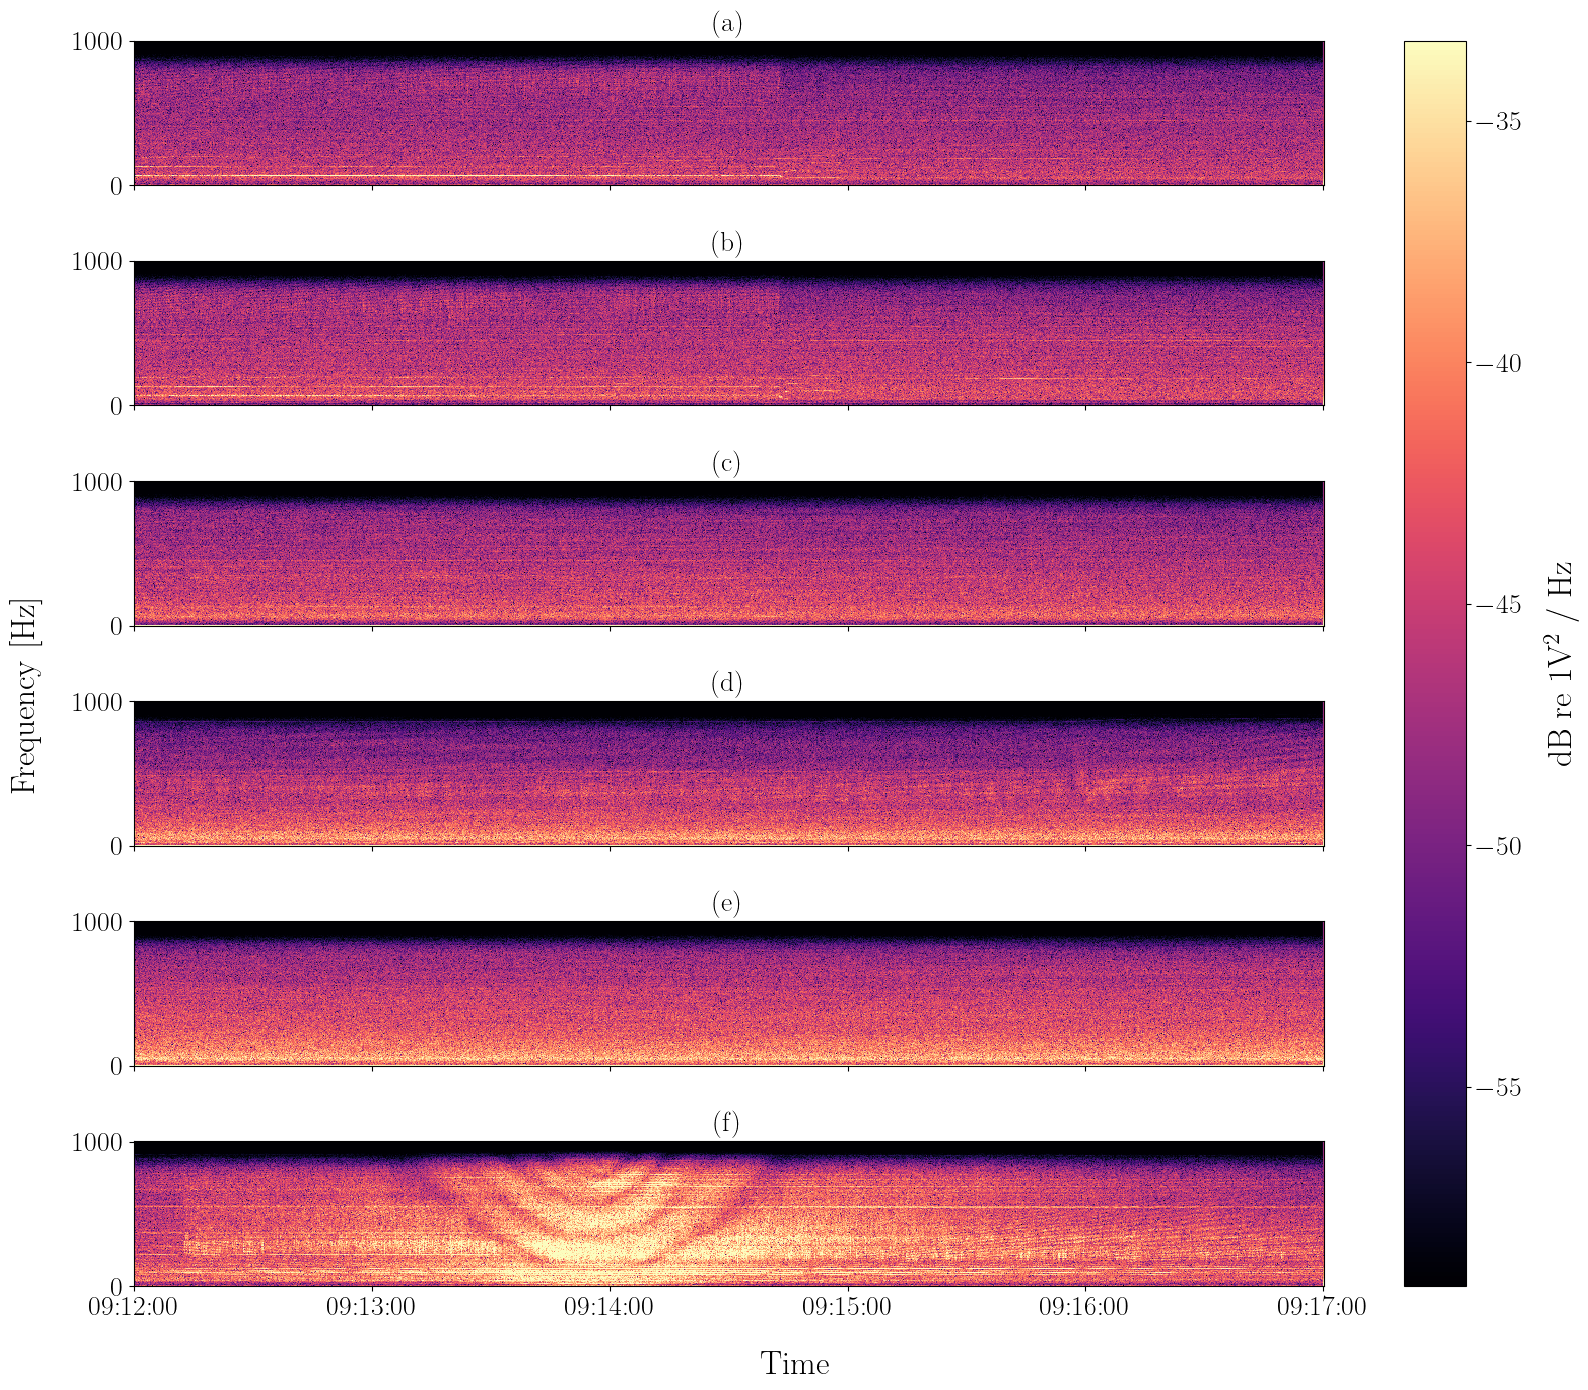

In [15]:
fig, axs = plot_spectrogram_section(ds_pressure_eoi, nperseg=2**10, noverlap=2**9, cmap="magma")

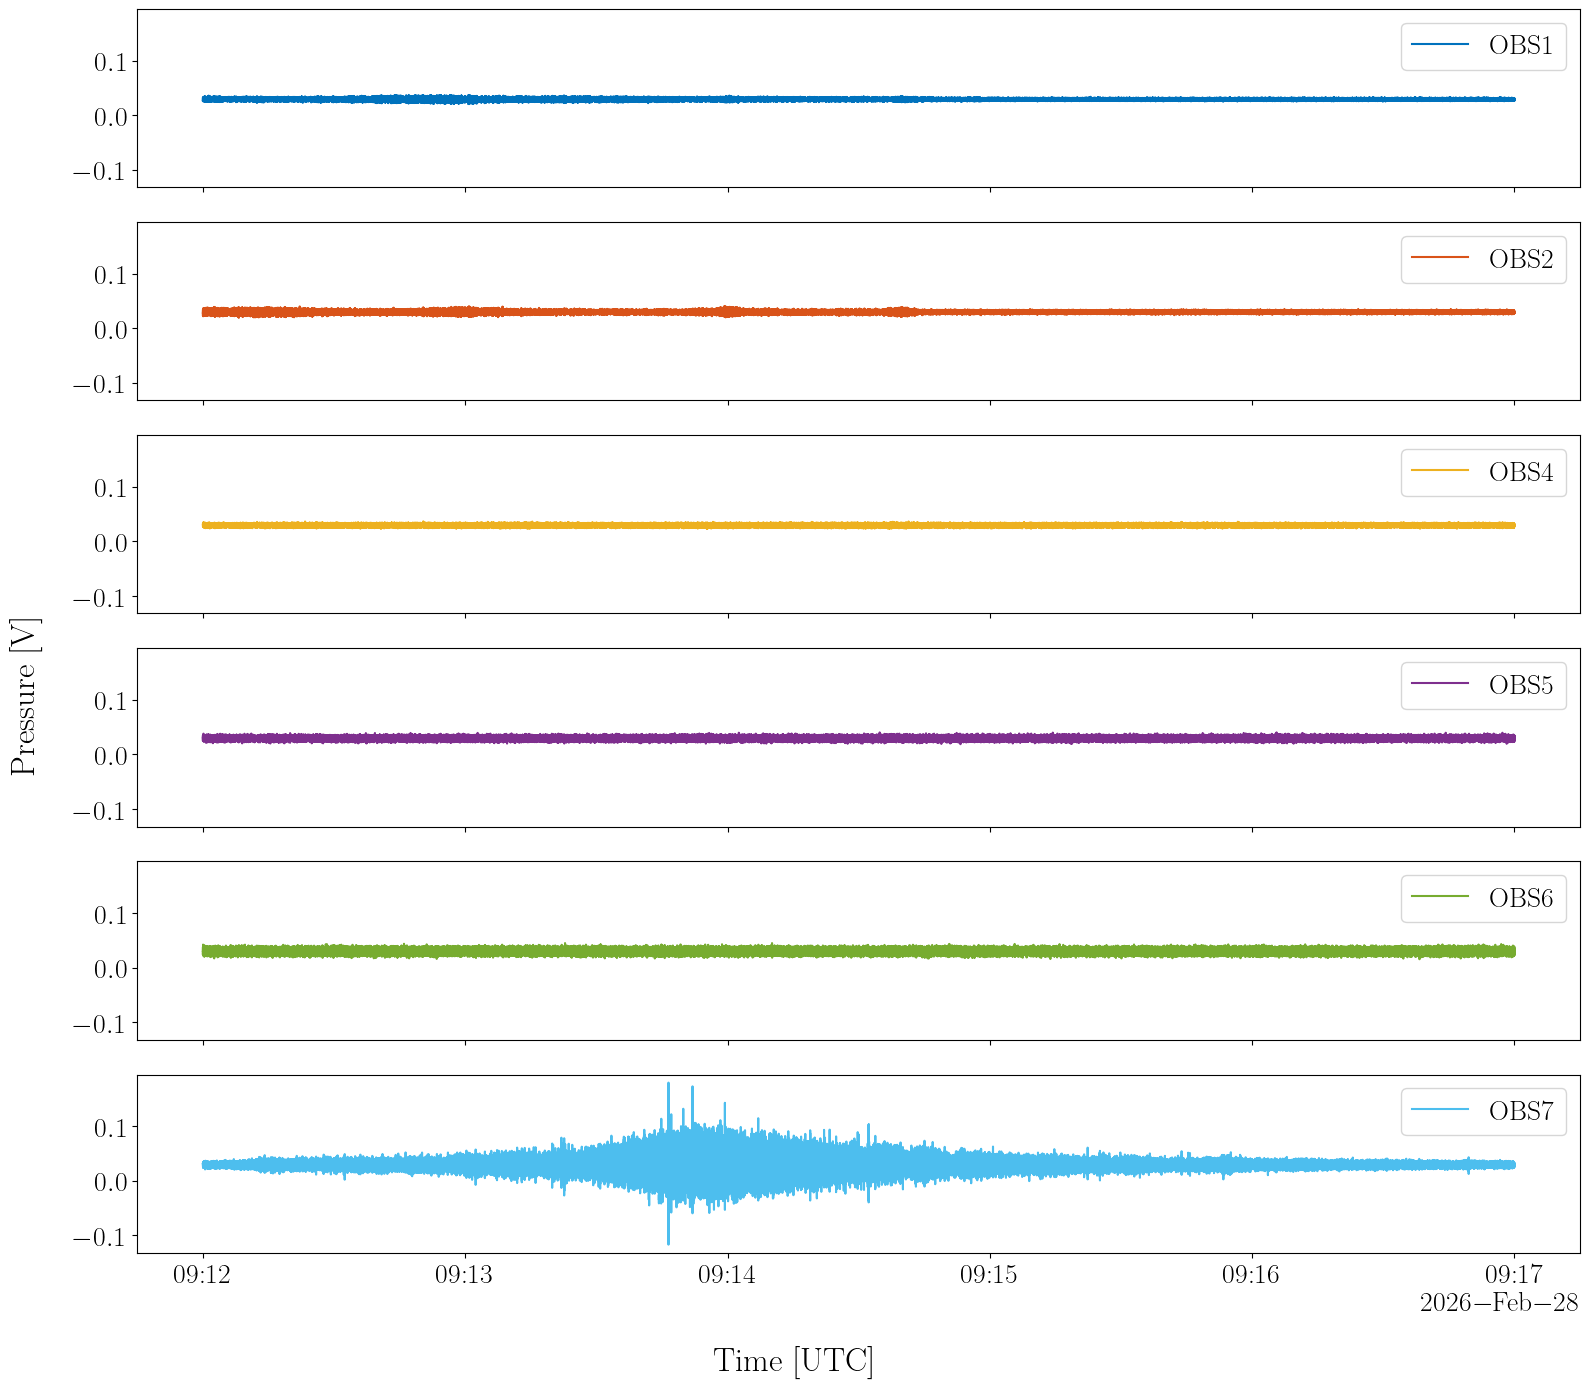

In [16]:
fig, axs = plot_pressure_section(ds_pressure_section=ds_pressure_eoi)

## AIS durant la période 

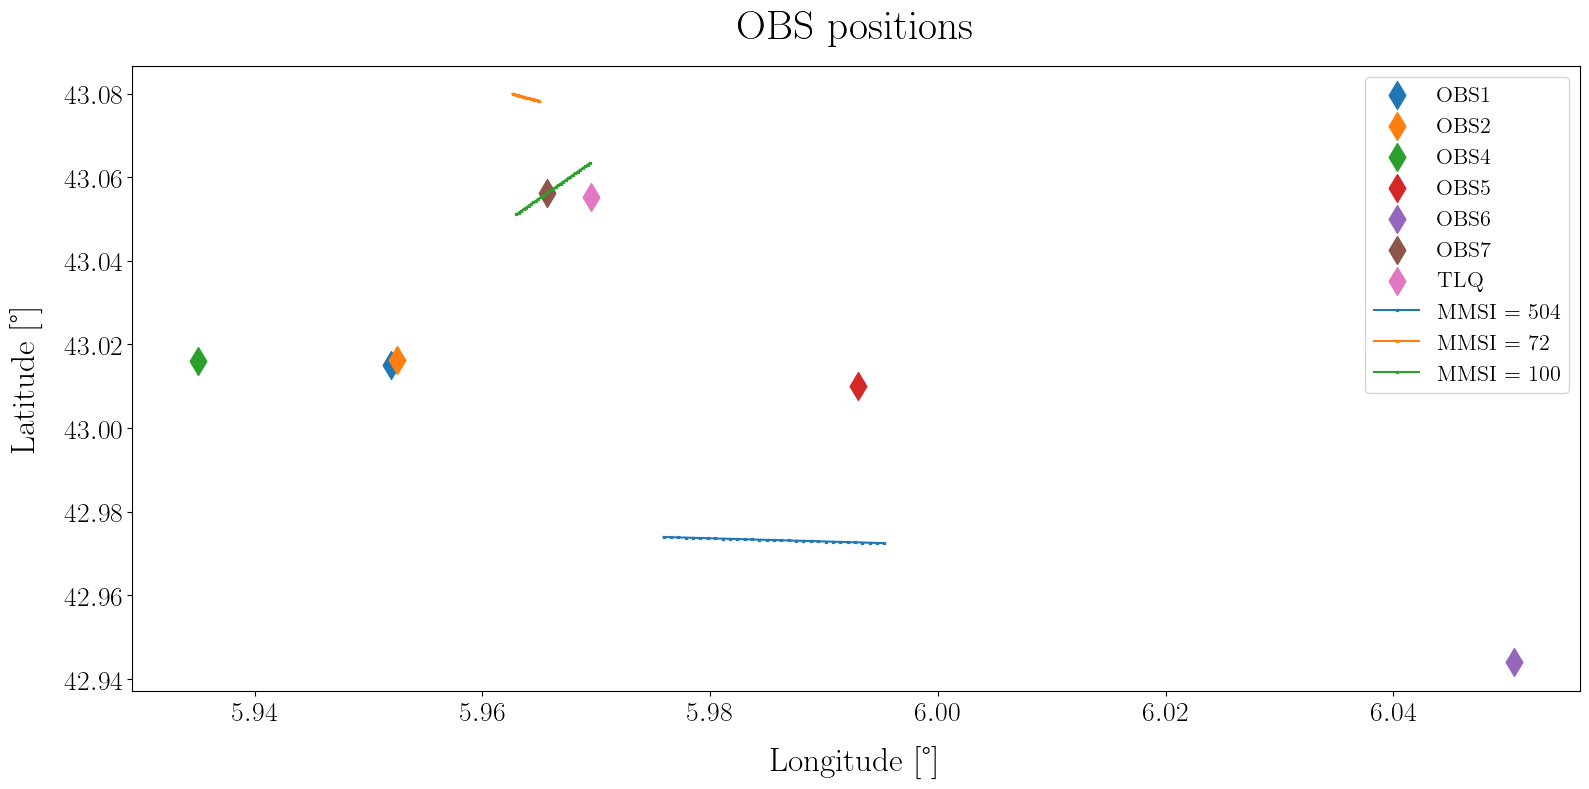

In [17]:
# Plot
fig, ax = plt.subplots(figsize=(16, 8))
plot_obs_pos(ds_pos_eoi, ax=ax)

for mmsi in ds_pos_eoi.mmsi.values:
    ds_pos_eoi_mmsi = ds_pos_eoi.sel(mmsi=mmsi)
    plt.plot(
        ds_pos_eoi_mmsi.ais_lon,
        ds_pos_eoi_mmsi.ais_lat,
        "-x",
        markersize=2,
        label=f"MMSI = {mmsi}",
    )

ax.legend(fontsize=16, loc="upper right", ncol=1)

## Calcul distance dans l'espace -> CPA théorique 

In [18]:
def get_dist_src_rcv(src_lon, src_lat, rcv_lon, rcv_lat):
    from pyproj import Geod

    geod = Geod(ellps="WGS84")

    # Cast the rcv position to the shape of the src positions
    lon_rcv = np.full(src_lon.size, rcv_lon)
    lat_rcv = np.full(src_lat.size, rcv_lat)

    # Compute geodesic distance
    _, _, horizontal_distance = geod.inv(
        lons1=src_lon, lats1=src_lat, lons2=lon_rcv, lats2=lat_rcv
    )

    return horizontal_distance


def get_distance_src_to_rcv(ds_pos_eoi):

    dist_ais_rcv = []
    for mmsi in ds_pos_eoi.mmsi.values:
        ds_pos_eoi_mmsi = ds_pos_eoi.sel(mmsi=mmsi)
        ais_lon = ds_pos_eoi_mmsi.ais_lon.values
        ais_lat = ds_pos_eoi_mmsi.ais_lat.values
        dist_ais_rcv_mmsi = []
        for rcv_id in ds_pos_eoi.rcv_id.values:

            rcv_lon_i = ds_pos_eoi.rcv_lon.sel(rcv_id=rcv_id)
            rcv_lat_i = ds_pos_eoi.rcv_lat.sel(rcv_id=rcv_id)

            d_ais_rcv = get_dist_src_rcv(ais_lon, ais_lat, rcv_lon_i, rcv_lat_i)

            dist_ais_rcv_mmsi.append(d_ais_rcv)

        dist_ais_rcv.append(np.asarray(dist_ais_rcv_mmsi))

    ds_pos_eoi["distance_ais_rcv"] = (
        ["mmsi", "rcv_id", "ais_datetime"],
        np.asarray(dist_ais_rcv),
    )

In [19]:
get_distance_src_to_rcv(ds_pos_eoi=ds_pos_eoi)
ds_pos_eoi

<xarray.Dataset> Size: 7kB
Dimensions:           (mmsi: 3, ais_datetime: 31, rcv_id: 7)
Coordinates:
  * mmsi              (mmsi) int64 24B 504 72 100
  * ais_datetime      (ais_datetime) datetime64[ns] 248B 2026-02-28T09:12:00 ...
  * rcv_id            (rcv_id) <U4 112B 'obs1' 'obs2' 'obs4' ... 'obs7' 'tlq'
Data variables:
    ais_lon           (mmsi, ais_datetime) float64 744B 5.976 5.977 ... 5.969
    ais_lat           (mmsi, ais_datetime) float64 744B 42.97 42.97 ... 43.06
    rcv_lon           (rcv_id) float64 56B ...
    rcv_lat           (rcv_id) float64 56B ...
    rcv_immersion     (rcv_id) int16 14B ...
    distance_ais_rcv  (mmsi, rcv_id, ais_datetime) float64 5kB 4.977e+03 ... ...
Attributes:
    description:              Positions AIS interpolées
    interpolation_time_step:  10s
    campagne:                 ACOUPLANE
    geodesic_frame:           WGS84

In [20]:
import scipy.signal as sp

# ds_pressure_eoi_select = ds_pressure_eoi.sel(obs_id=["obs1", "obs2", "obs4", "obs6"])
ds_pressure_eoi_select = ds_pressure_eoi

nperseg = 2**10
noverlap = 2**9

sxx_plot = []
tt_datetime = None
ff = None

for i, obs_id in enumerate(ds_pressure_eoi_select.obs_id.values):
    pressure = ds_pressure_eoi_select[f"pressure_{obs_id}"]
    # Derive stft
    ff, tt, stft = sp.stft(
        pressure.values,
        fs=ds_pressure_eoi_select.fs,
        window="hann",
        nperseg=nperseg,
        noverlap=noverlap,
        scaling="psd",  # V^2 / Hz
    )
    sxx = 10 * np.log10(np.abs(stft) + 1e-6)  # dB re V**2 / Hz
    sxx_plot.append(sxx)

    # Datetime vector of the first OBS is used for the shared time axis
    if i == 0:
        t0 = pd.to_datetime(
            ds_pressure_eoi_select[f"time_{obs_id}"].values[0]
        ).to_pydatetime()
        tt_datetime = pd.to_datetime(t0) + pd.to_timedelta(tt, unit="s")

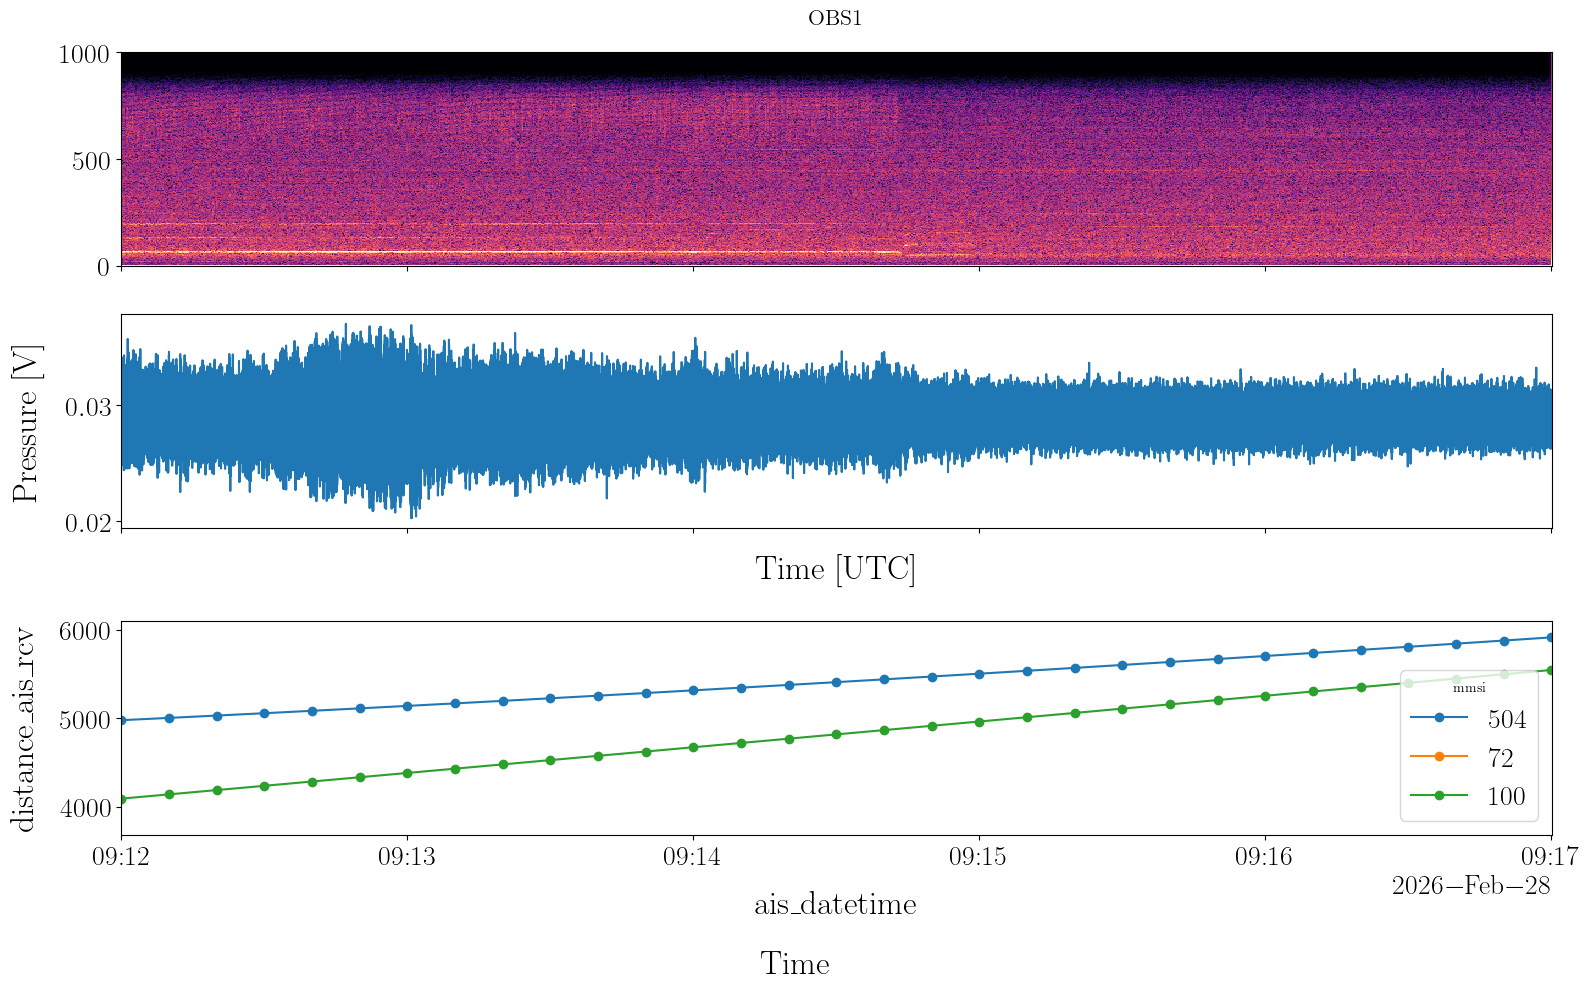

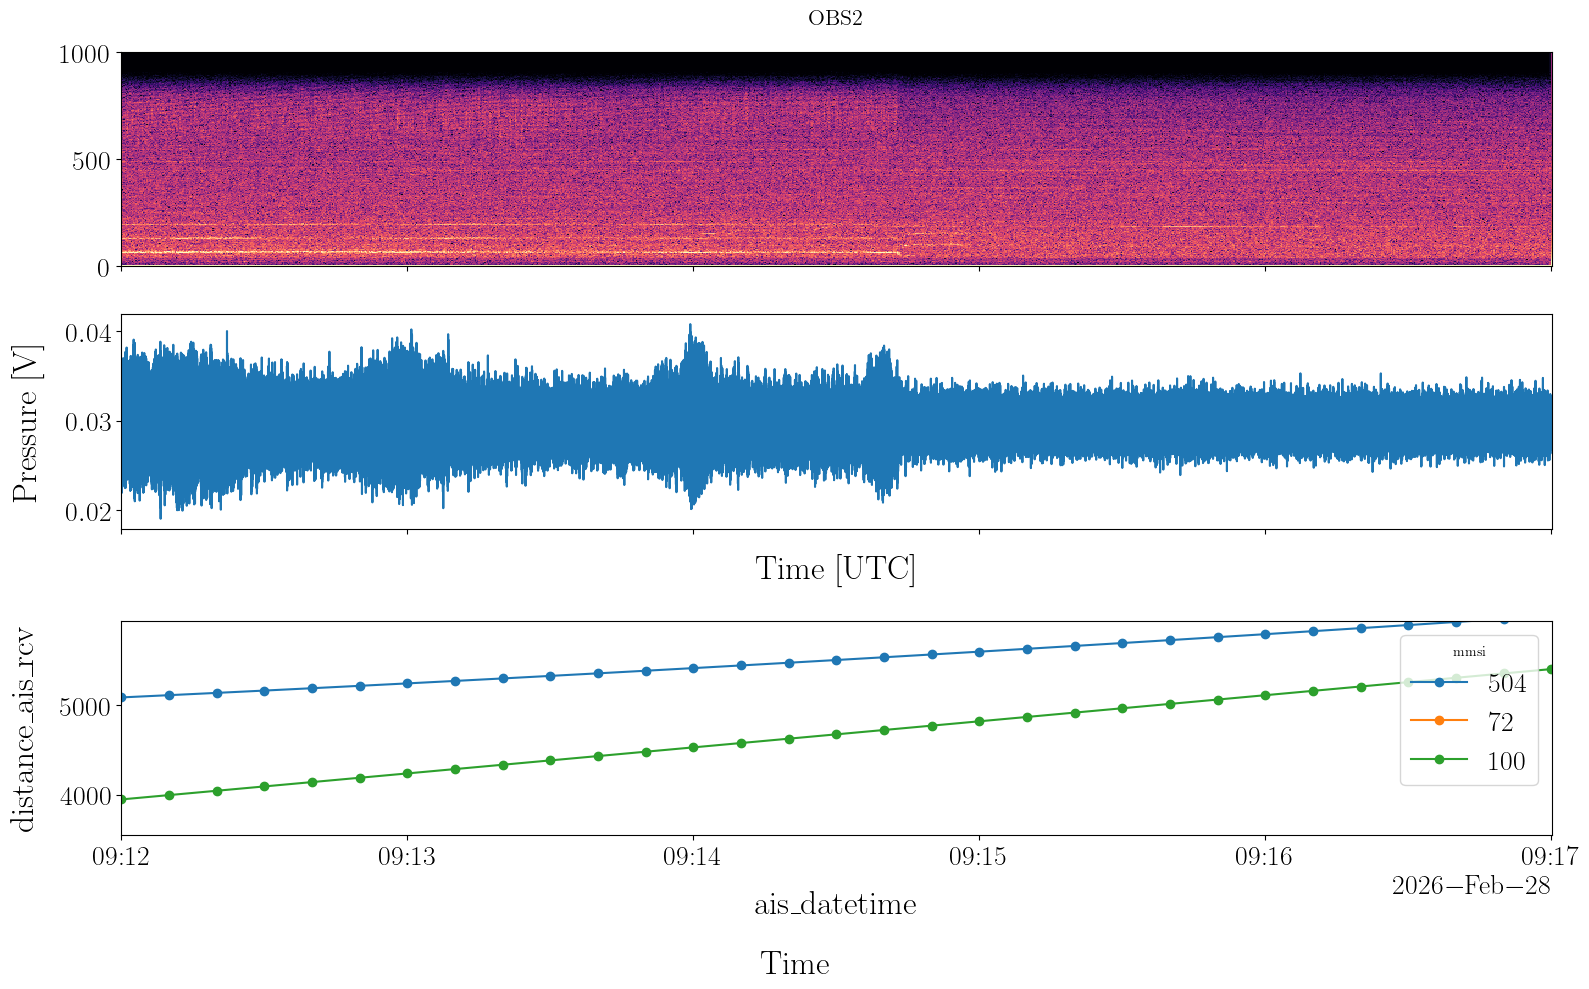

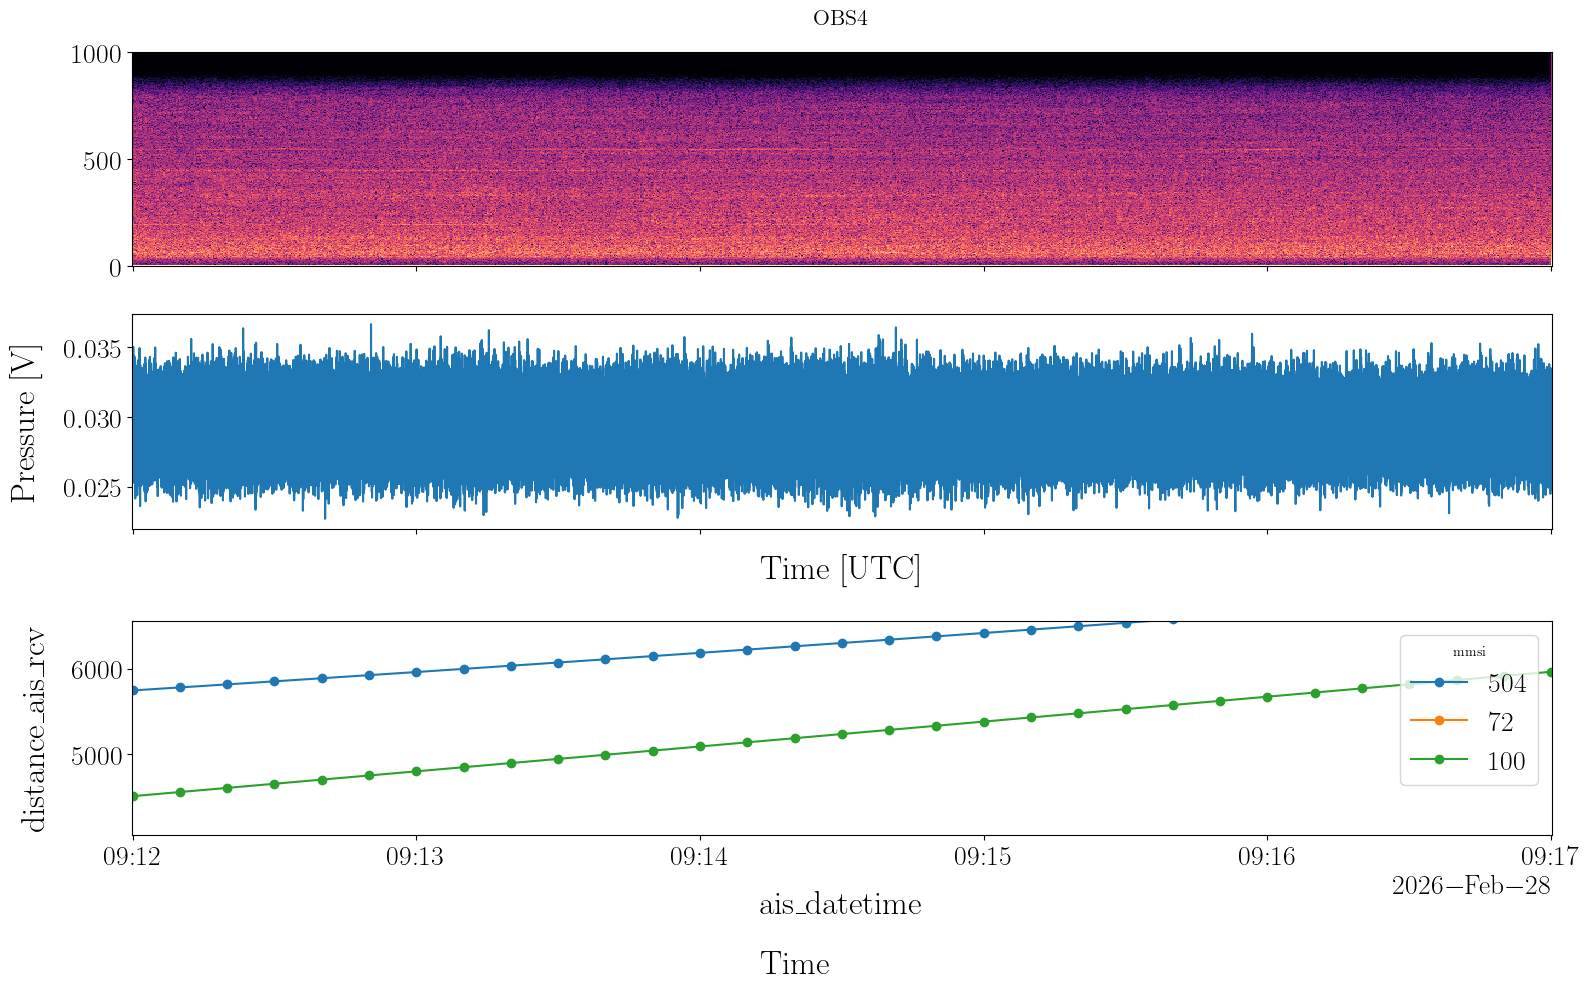

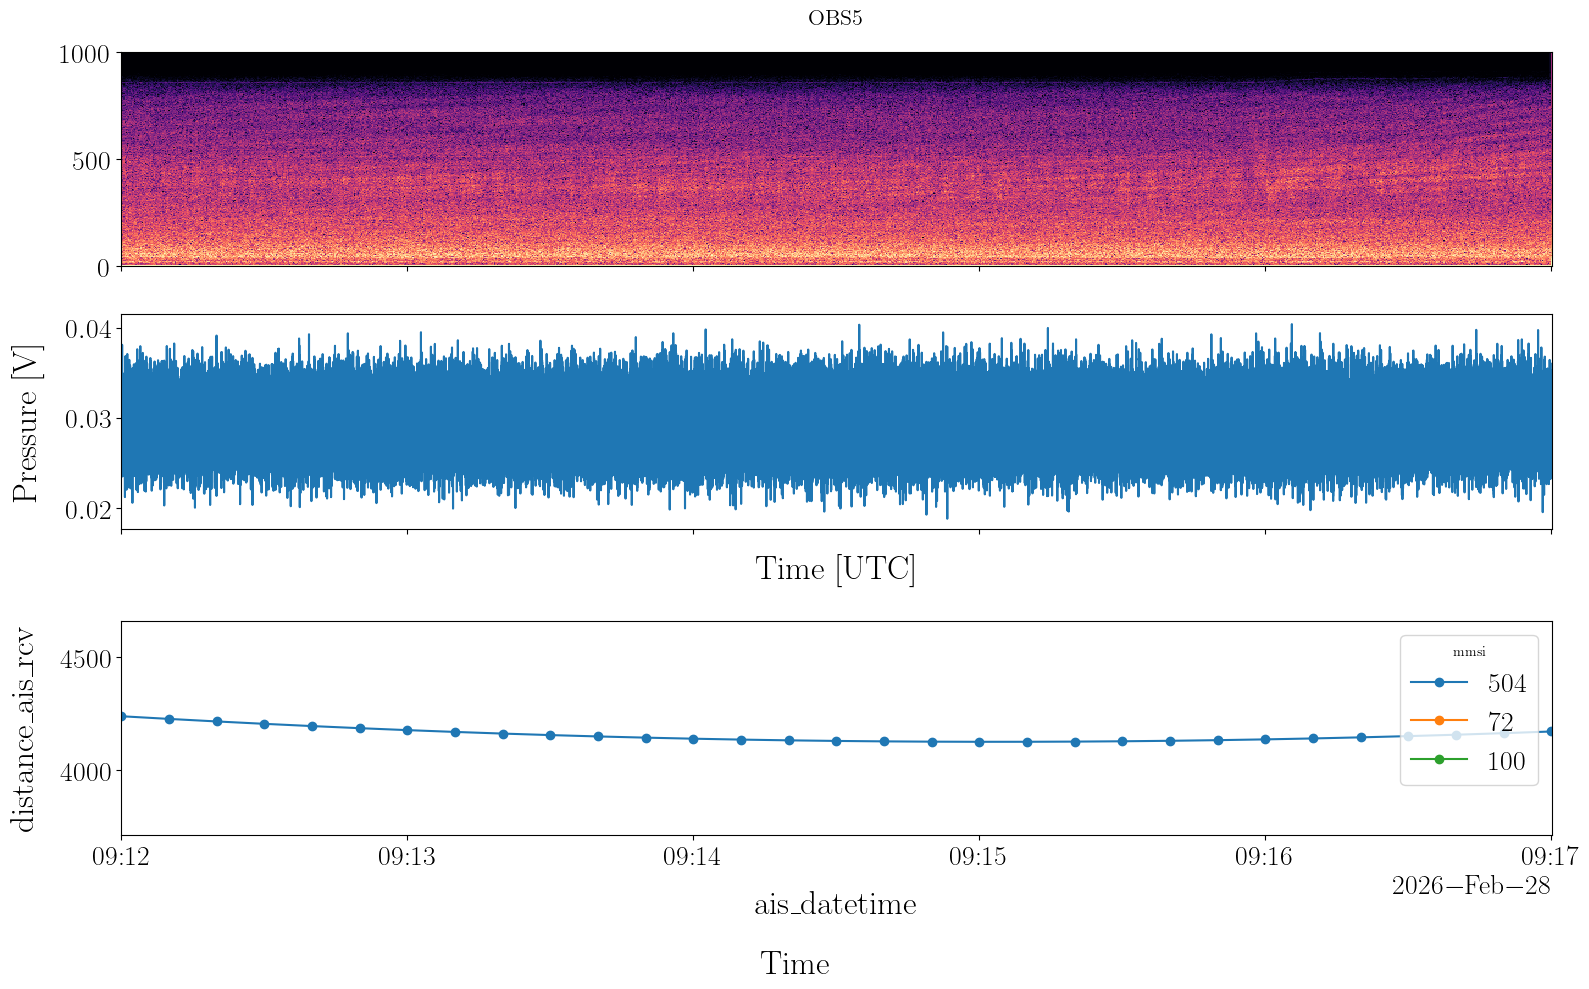

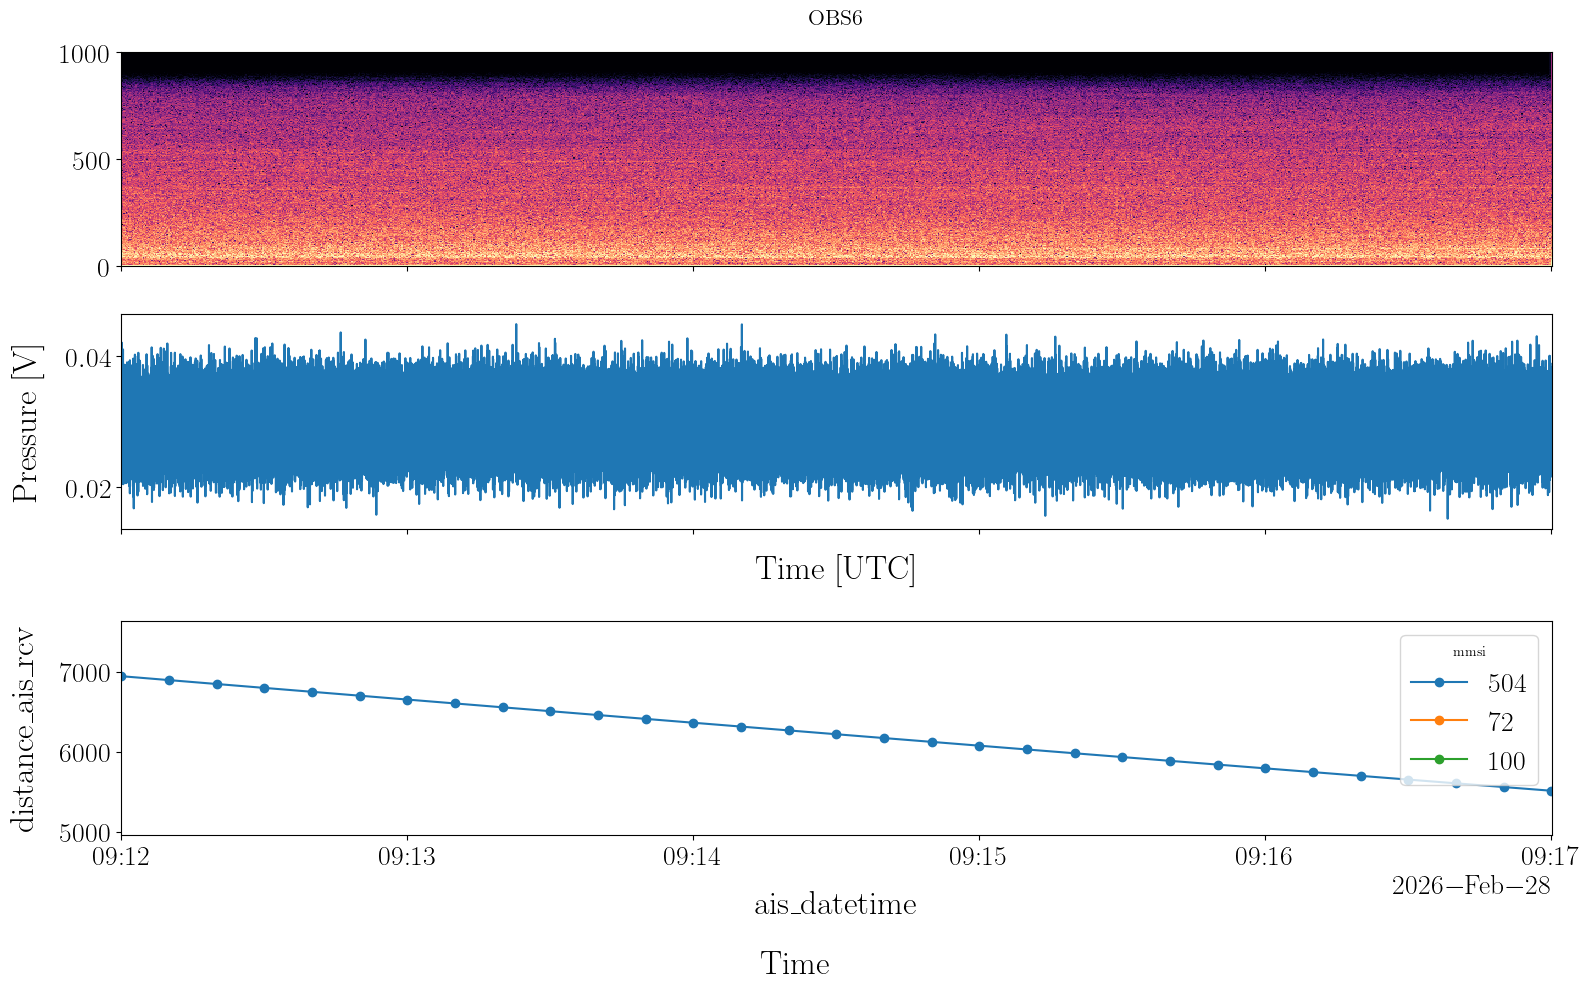

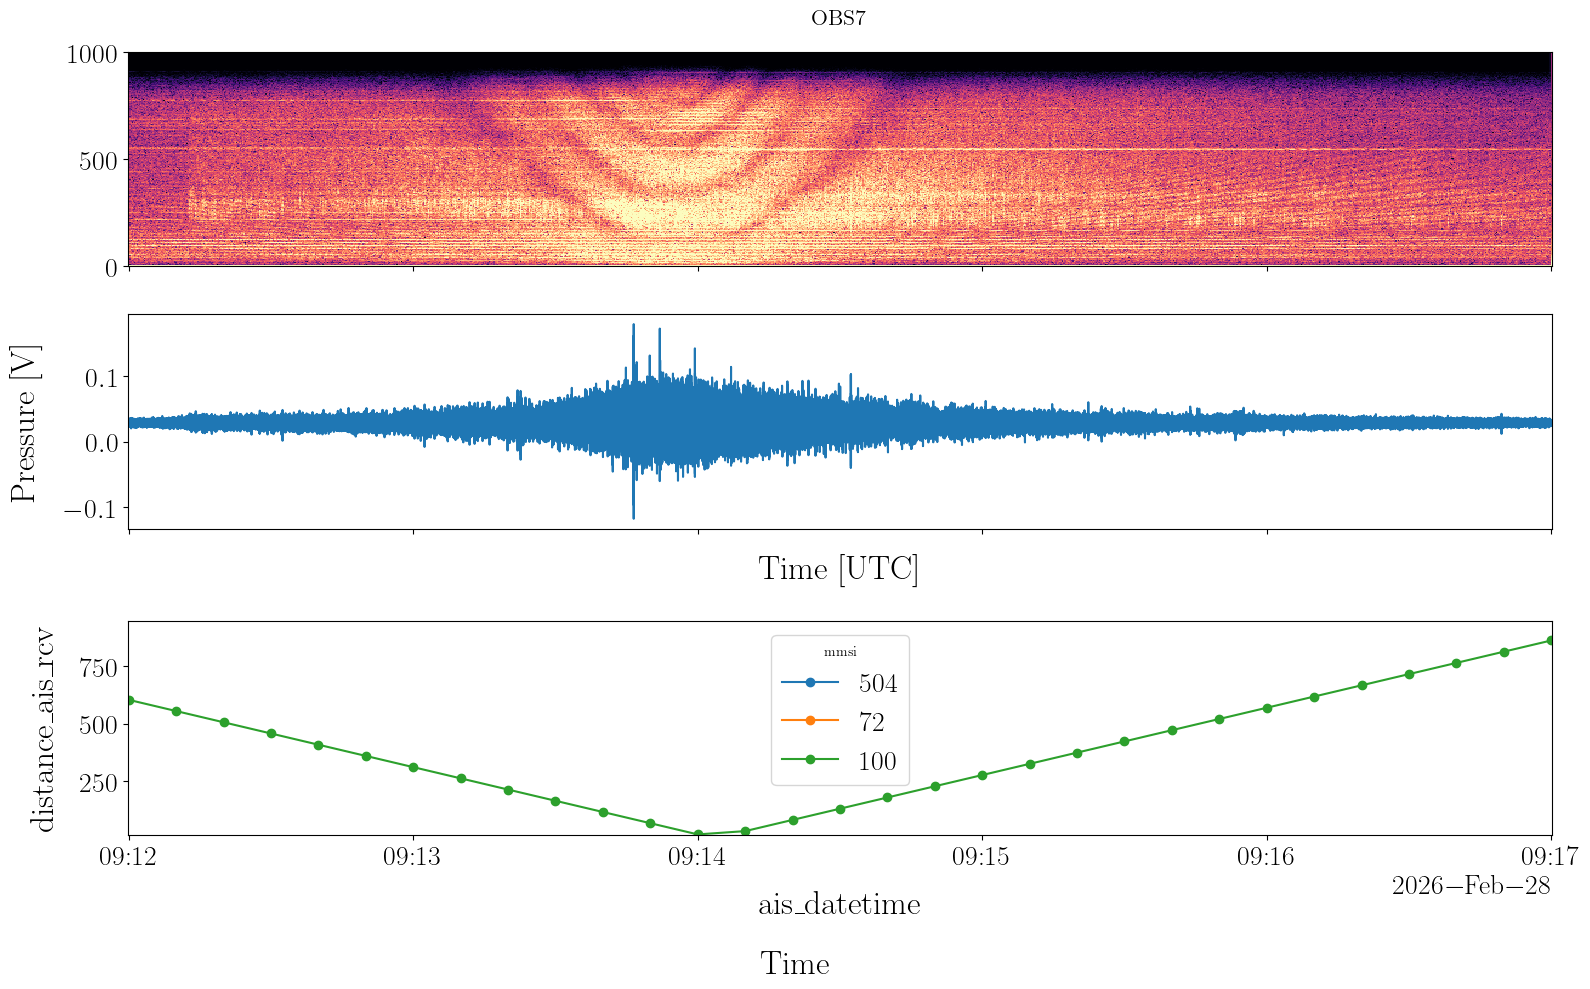

In [21]:
# Plot
cmap = "magma"
sxx_plot = np.array(sxx_plot)
vmin = np.percentile(sxx_plot, 10)
vmax = np.percentile(sxx_plot, 99)


for i, obs_id in enumerate(ds_pressure_eoi_select.obs_id.values):
    fig, axs = plt.subplots(
        nrows=3,
        ncols=1,
        figsize=(16, 10),
        sharey=False,
        sharex=True,
    )

    im = axs[0].pcolormesh(
        tt_datetime, ff, sxx_plot[i, ...], cmap=cmap, vmin=vmin, vmax=vmax
    )

    ds_pressure_eoi[f"pressure_{obs_id}"].plot(ax=axs[1])

    ds_pos_eoi.distance_ais_rcv.sel(rcv_id=obs_id).plot(
        x="ais_datetime", hue="mmsi", ax=axs[2], marker="o"
    )

    axs[0].set_title(f"{obs_id.upper()}", fontsize=16)
    axs[1].set_title("")
    axs[2].set_title("")
    # axs[2].set_ylim(9000, 10500)

    # min_d = np.min([
    #     ds_pos_eoi.distance_ais_rcv.sel(rcv_id=obs_id).sel(mmsi=m).min().values
    #     for m in ds_pos_eoi.distance_ais_rcv.sel(rcv_id=obs_id).mmsi.values
    # ])
    closest_mmsi = ds_pos_eoi.mmsi.values[
        ds_pos_eoi.distance_ais_rcv.sel(rcv_id=obs_id)
        .argmin(dim=["ais_datetime", "mmsi"])["mmsi"]
        .values
    ]
    ymin, ymax = ds_pos_eoi.distance_ais_rcv.sel(rcv_id=obs_id, mmsi=closest_mmsi).min().values * 0.9, ds_pos_eoi.distance_ais_rcv.sel(rcv_id=obs_id, mmsi=closest_mmsi).max().values * 1.1
    axs[2].set_ylim(ymin, ymax)

    fig.supxlabel("Time")

# clabel = r"dB re 1V$^2$ / Hz"
# fig.colorbar(
#     im,
#     ax=axs.ravel().tolist(),
#     label=clabel,
#     orientation="vertical",
#     fraction=1.0,
#     pad=0.03,
# )

# for ax in axs:
#     ax.set_xlabel("")
#     ax.set_ylabel("")
# ax.set_title("")
# fig.supxlabel("Time")
# fig.supylabel("Frequency [Hz]")

# set_subfigures_abc_labels(
#     axs, x_pos=0.5, y_pos=1.02, fontsize=20, ha="center", va="bottom"
# )